<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Risk/EVT_VaR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Steps
'''
1. Generate data from t student(with known parameters we will know the tail index)
2. Make losses
3. Above a threshold, get excess losses
4. Fit the GPD
'''

import numpy as np
import pandas as pd
from scipy.stats import genpareto, t, probplot
import matplotlib.pyplot as plt
import yfinance as yf
import datetime as dt

In [8]:

big = t.rvs(4, size=100000, random_state=np.random.default_rng(0))
#plt.hist(big, bins=10000)
L0 = -big
u0 = np.quantile(L0, 0.99)
xi0 ,_, _ = genpareto.fit(L0[L0 > u0] - u0, floc=0)
print(f"t(nu=4) data: fitted xi = {xi0:.3f}   theory 1/nu = {1/4:.3f}")

t(nu=4) data: fitted xi = 0.186   theory 1/nu = 0.250


In [9]:
# Download and close prices/returns data for a time period
years = 15
start_date = dt.datetime.today() - dt.timedelta(days=365*years)
end_date = dt.datetime.today()
#start_date = '2008-04-28'
#end_date = '2023-04-25'

tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']
adj_close = pd.DataFrame()

for ticker in tickers:
  # Use multi_level_index=False to prevent MultiIndex columns and retrieve the adjusted 'Close'
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
  adj_close[ticker] = data['Close']

# Log Returns
log_ret = np.log(adj_close / adj_close.shift(1))
log_ret.dropna(inplace=True)

# Portfolio
# Weighing equally weighted
weights = np.array([1/len(tickers)]*len(tickers))

# Portfolio historical returns
p_ret = (log_ret * weights).sum(axis=1)

/tmp/ipykernel_1948/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1948/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1948/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1948/3861931046.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_leve

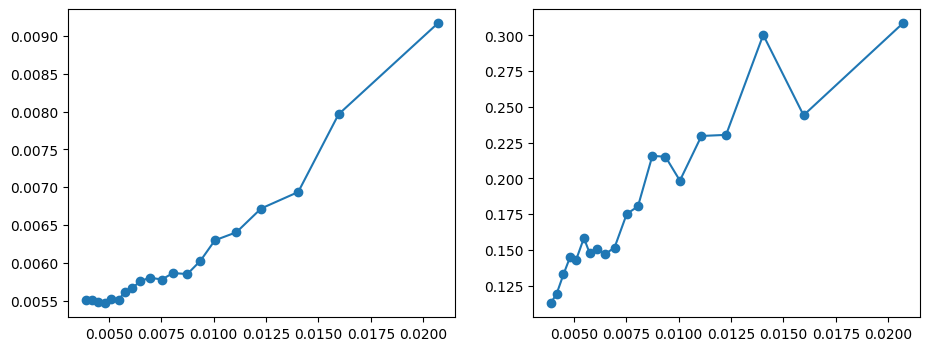

In [10]:
'''
x is the returns of the portfolio and l are the losses
us is the threshold of losses

Based on the plot of us, we decide the the threshold limit (where mean_ex is decreasing smoothly)
(and the xis(eta) is also smoothly staying in a range)

once these are decided, the threshold is Decided and we go to the next step
'''
x = p_ret.values
l = -x

us = np.quantile(l, np.linspace(0.8, .99, 20))

mean_ex = [np.mean(l[l > u] - u) for u in us]
xis = [genpareto.fit(l[l > u] - u, floc=0)[0] for u in us]
n_exc = [(l>u).sum() for u in us]


fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(us, mean_ex,'o-')

ax[1].plot(us, xis, 'o-')

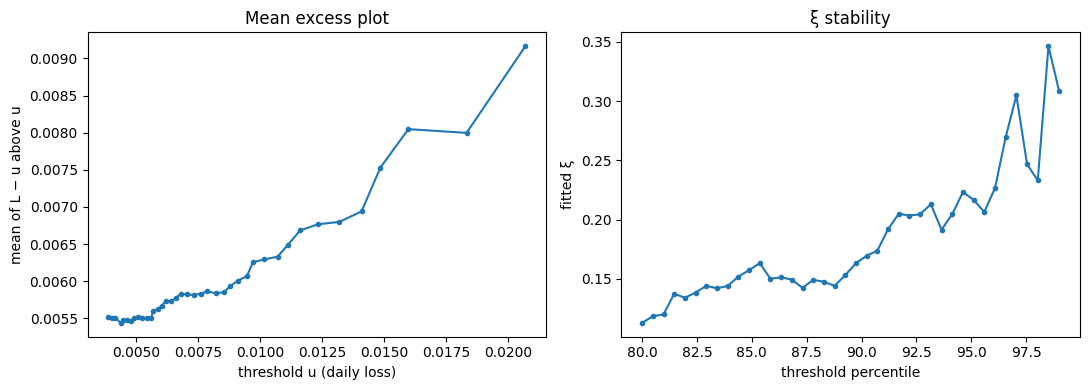

80%  u = 0.390%  excesses =  754  xi = 0.113
81%  u = 0.418%  excesses =  717  xi = 0.120
82%  u = 0.450%  excesses =  680  xi = 0.134
83%  u = 0.481%  excesses =  644  xi = 0.144
84%  u = 0.508%  excesses =  607  xi = 0.144
85%  u = 0.544%  excesses =  570  xi = 0.157
86%  u = 0.571%  excesses =  534  xi = 0.150
87%  u = 0.605%  excesses =  497  xi = 0.149
88%  u = 0.643%  excesses =  460  xi = 0.149
89%  u = 0.681%  excesses =  423  xi = 0.144
90%  u = 0.734%  excesses =  387  xi = 0.163
91%  u = 0.788%  excesses =  350  xi = 0.174
92%  u = 0.854%  excesses =  313  xi = 0.205
93%  u = 0.911%  excesses =  277  xi = 0.205
94%  u = 0.973%  excesses =  240  xi = 0.191
95%  u = 1.071%  excesses =  203  xi = 0.223
96%  u = 1.163%  excesses =  167  xi = 0.206
97%  u = 1.320%  excesses =  130  xi = 0.270
98%  u = 1.485%  excesses =   93  xi = 0.247
99%  u = 1.833%  excesses =   57  xi = 0.346


In [46]:
x = p_ret.values
L = -x                                          # daily losses: crash days are large positive numbers

qs = np.linspace(0.80, 0.99, 40)                # 40 candidate threshold levels, 80th to 99th percentile
us = np.quantile(L, qs)                         # the loss value at each of those levels

mean_excess = [np.mean(L[L > u] - u) for u in us]
xis = [genpareto.fit(L[L > u] - u, floc=0)[0] for u in us]
n_exc = [(L > u).sum() for u in us]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(us, mean_excess, "o-", ms=3)
ax[0].set_title("Mean excess plot")
ax[0].set_xlabel("threshold u (daily loss)")
ax[0].set_ylabel("mean of L − u above u")

ax[1].plot(qs * 100, xis, "o-", ms=3)
ax[1].set_title("ξ stability")
ax[1].set_xlabel("threshold percentile")
ax[1].set_ylabel("fitted ξ")
plt.tight_layout(); plt.show()

for q, u, k, xi_ in zip(qs[::2], us[::2], n_exc[::2], xis[::2]):
    print(f"{q:.0%}  u = {u:.3%}  excesses = {k:4d}  xi = {xi_:.3f}")

In [6]:
uT = np.quantile(l, .95)
uT

np.float64(0.011089869487245494)

3767 189


((array([1.80770295e-05, 4.40167031e-05, 7.04087328e-05, 9.69751761e-05,
         1.23718134e-04, 1.50639746e-04, 1.77742186e-04, 2.05027669e-04,
         2.32498451e-04, 2.60156823e-04, 2.88005124e-04, 3.16045730e-04,
         3.44281064e-04, 3.72713590e-04, 4.01345822e-04, 4.30180316e-04,
         4.59219678e-04, 4.88466564e-04, 5.17923678e-04, 5.47593776e-04,
         5.77479667e-04, 6.07584213e-04, 6.37910334e-04, 6.68461003e-04,
         6.99239254e-04, 7.30248180e-04, 7.61490935e-04, 7.92970735e-04,
         8.24690863e-04, 8.56654665e-04, 8.88865557e-04, 9.21327025e-04,
         9.54042626e-04, 9.87015990e-04, 1.02025082e-03, 1.05375091e-03,
         1.08752012e-03, 1.12156238e-03, 1.15588174e-03, 1.19048232e-03,
         1.22536831e-03, 1.26054401e-03, 1.29601382e-03, 1.33178223e-03,
         1.36785382e-03, 1.40423329e-03, 1.44092543e-03, 1.47793516e-03,
         1.51526749e-03, 1.55292756e-03, 1.59092063e-03, 1.62925206e-03,
         1.66792737e-03, 1.70695219e-03, 1.74633228

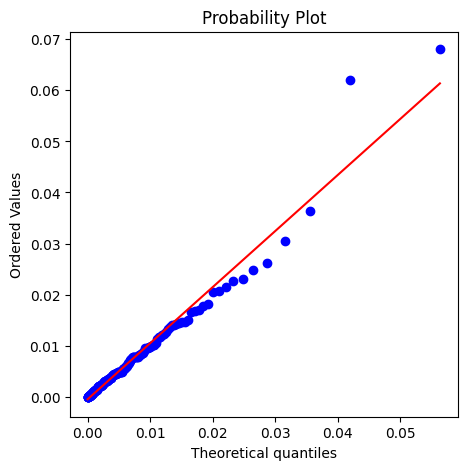

In [25]:
'''
now we decide the threhold limit, which is 95%
and based on that the threshold for losses
uThreshold = np.quantile(l, .95)
'''
thresh = 0.95
u_thresh = np.quantile(l, thresh)
ex_loss = l[l > uT] - uT
xi, _, beta = genpareto.fit(ex_loss, floc=0)

n, nu = len(l), len(ex_loss)
print(f'{n} {nu}')

# Q-Q Plot
fig, ax = plt.subplots(figsize=(5,5))
probplot(ex_loss, dist=genpareto, sparams=(xi, 0, beta), plot=ax)


In [29]:
'''
once the parameters are estimated
use the var formula for calculation
var: with known xi, beta we can calculate VaR
'''
c = .99
evt_var = uT + beta / xi * (((n / nu) * (1 - c)) ** (-xi) - 1)

np.float64(1489.217042148437)

0.001489

In [15]:
xi

np.float64(0.22963646722281983)

u = 1.109%   excesses = 189 of 3767   (5.0% of days)
xi = 0.230 ± 0.179   beta = 0.00493
mean excess implied by fit = 0.639%   observed = 0.641%
t fit: 1/nu = 0.005


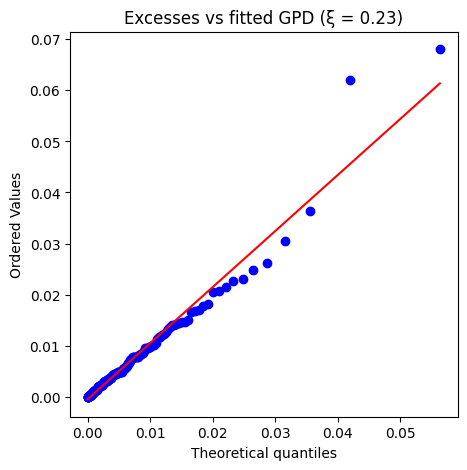

In [20]:
from scipy.stats import genpareto, probplot

q_u = 0.95                                   # chosen from the stability plot
u = np.quantile(l, q_u)                      # threshold loss, about 1.07%
exc = l[l > u] - u                           # excesses beyond the threshold

xi, _, beta = genpareto.fit(exc, floc=0)
n, Nu = len(l), len(exc)
se_xi = (1 + xi) / np.sqrt(Nu)               # approximate standard error of xi

print(f"u = {u:.3%}   excesses = {Nu} of {n}   ({Nu/n:.1%} of days)")
print(f"xi = {xi:.3f} ± {2*se_xi:.3f}   beta = {beta:.5f}")
print(f"mean excess implied by fit = {beta/(1-xi):.3%}   observed = {exc.mean():.3%}")
print(f"t fit: 1/nu = {1/nu:.3f}")           # check nu is your real fit, not 4

# QQ-plot: excesses against the fitted GPD
fig, ax = plt.subplots(figsize=(5, 5))
probplot(exc, dist=genpareto, sparams=(xi, 0, beta), plot=ax)
ax.set_title(f"Excesses vs fitted GPD (ξ = {xi:.2f})")
plt.show()